¡Éxito! Se encontraron 57812 reglas de asociación.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,antecedents,consequents,support,confidence,lift
0,(Arroz),(Aceite),0.211,0.950450,4.379956
1,(Aceite),(Arroz),0.211,0.972350,4.379956
2,(Azúcar),(Aceite),0.071,0.855422,3.942035
3,(Aceite),(Azúcar),0.071,0.327189,3.942035
4,(Aceite),(Café en Grano),0.069,0.317972,0.960642
5,(Cebolla),(Aceite),0.146,0.598361,2.757422
6,(Aceite),(Cebolla),0.146,0.672811,2.757422
7,(Chile Verde),(Aceite),0.146,0.417143,1.922317
8,(Aceite),(Chile Verde),0.146,0.672811,1.922317
9,(Detergente),(Aceite),0.071,0.550388,2.536348


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

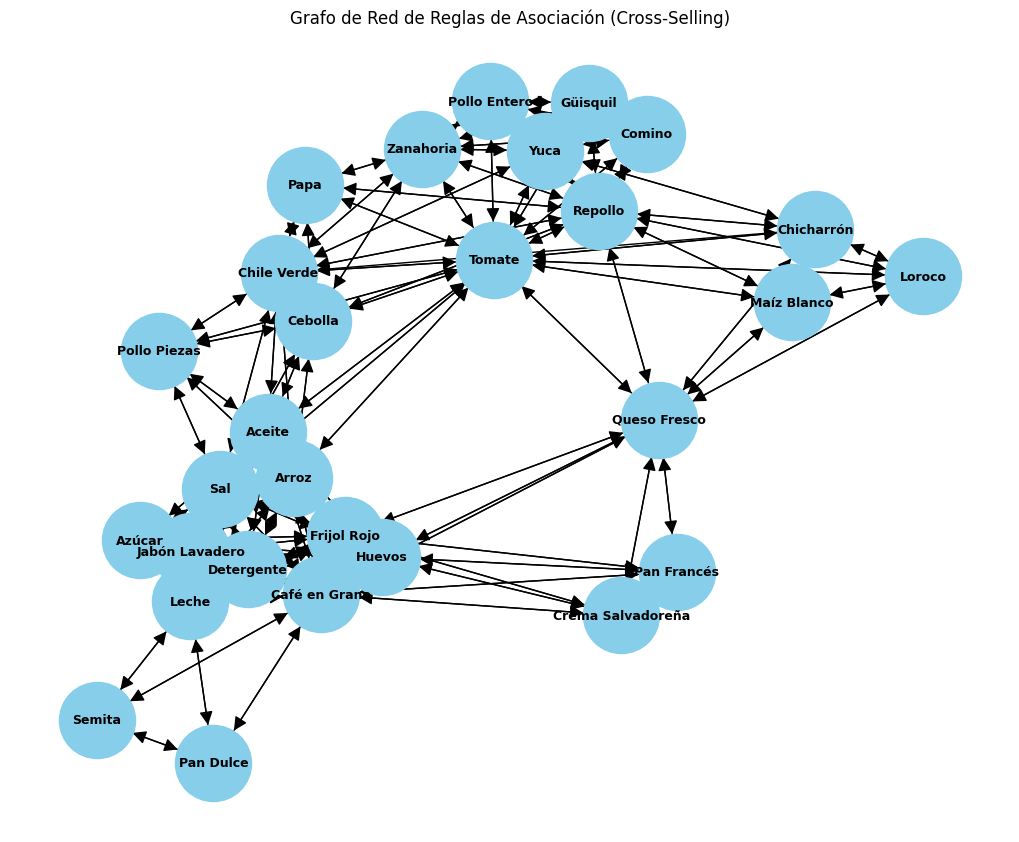

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [1]:
!pip install mlxtend

import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder
import matplotlib.pyplot as plt
import networkx as nx

df_trans = pd.read_csv("transacciones_mercado.csv")

transacciones_lista = df_trans['productos'].dropna().apply(lambda x: [p.strip() for p in x.split(';') if p.strip()])
te = TransactionEncoder()
te_ary = te.fit(transacciones_lista).transform(transacciones_lista)
df_onehot = pd.DataFrame(te_ary, columns=te.columns_)

frequent_itemsets = apriori(df_onehot, min_support=0.05, use_colnames=True)
rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.30)

print(f"¡Éxito! Se encontraron {len(rules)} reglas de asociación.")
display(rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(10))

plt.figure(figsize=(10, 8))
G = nx.DiGraph()
for idx, row in rules.iterrows():
    ant = list(row['antecedents'])[0]
    cons = list(row['consequents'])[0]
    G.add_edge(ant, cons, weight=row['lift'])

pos = nx.spring_layout(G, k=0.5, seed=42)
nx.draw(G, pos, with_labels=True, node_size=3000, node_color="skyblue",
        font_size=9, font_weight="bold", arrows=True, arrowsize=20)
plt.title("Grafo de Red de Reglas de Asociación (Cross-Selling)")
plt.tight_layout()
plt.savefig("grafo_red_asociacion.png")
plt.show()